In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


## 1. Load Preprocessed Data

In [3]:
# Load the preprocessed dataset
print("📂 Loading chickweight_preprocessed.csv...")
df = pd.read_csv('../data/chickweight_preprocessed.csv')

print(f"✅ Loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"\n📋 Columns: {df.columns.tolist()}")
print(f"\n📊 First 10 rows:")
df.head(10)

📂 Loading chickweight_preprocessed.csv...
✅ Loaded: 578 rows, 2 columns

📋 Columns: ['weight', 'Time']

📊 First 10 rows:


,weight,Time
0,42,0
1,51,2
2,59,4
3,64,6
4,76,8
5,93,10
6,106,12
7,125,14
8,149,16
9,171,18


In [3]:
# Check data info
print("📊 Dataset Information:")
print(df.info())

print("\n📈 Basic Statistics:")
print(df.describe())

print("\n❓ Missing Values:")
print(df.isnull().sum())

📊 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 578 entries, 0 to 577
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   weight  578 non-null    int64
 1   Time    578 non-null    int64
dtypes: int64(2)
memory usage: 9.2 KB
None

📈 Basic Statistics:
           weight        Time
count  578.000000  578.000000
mean   121.818339   10.717993
std     71.071960    6.758400
min     35.000000    0.000000
25%     63.000000    4.000000
50%    103.000000   10.000000
75%    163.750000   16.000000
max    373.000000   21.000000

❓ Missing Values:
weight    0
Time      0
dtype: int64


## 2. Exploratory Data Analysis

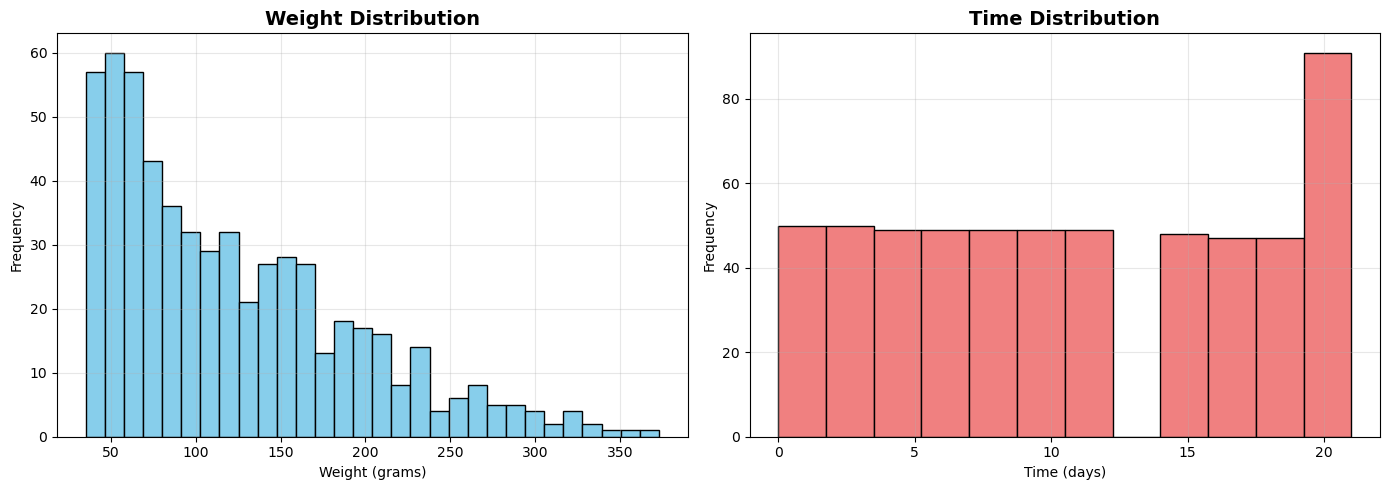

✅ Weight ranges from 35g to 373g
✅ Time ranges from 0 to 21 days


In [4]:
# Visualize weight distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Weight distribution
axes[0].hist(df['weight'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_title('Weight Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Weight (grams)')
axes[0].set_ylabel('Frequency')
axes[0].grid(alpha=0.3)

# Time distribution
axes[1].hist(df['Time'], bins=12, color='lightcoral', edgecolor='black')
axes[1].set_title('Time Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Frequency')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"✅ Weight ranges from {df['weight'].min()}g to {df['weight'].max()}g")
print(f"✅ Time ranges from {df['Time'].min()} to {df['Time'].max()} days")

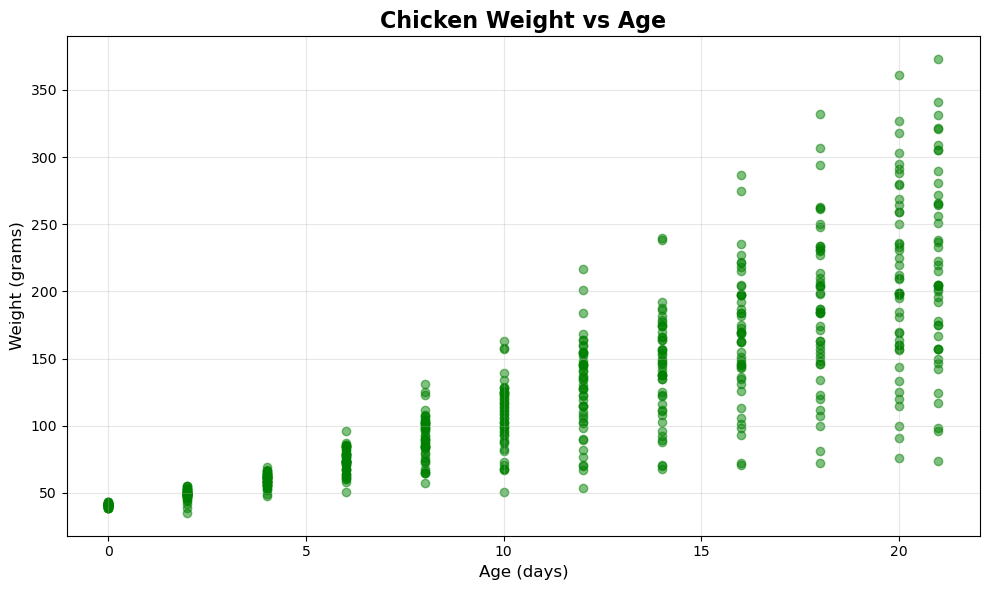


🔗 Correlation between Time and Weight: 0.8371
✅ Strong positive correlation - Good for prediction!


In [5]:
# Scatter plot: Weight vs Time
plt.figure(figsize=(10, 6))
plt.scatter(df['Time'], df['weight'], alpha=0.5, color='green')
plt.title('Chicken Weight vs Age', fontsize=16, fontweight='bold')
plt.xlabel('Age (days)', fontsize=12)
plt.ylabel('Weight (grams)', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = df['Time'].corr(df['weight'])
print(f"\n🔗 Correlation between Time and Weight: {correlation:.4f}")
if correlation > 0.7:
    print("✅ Strong positive correlation - Good for prediction!")

## 3. Feature Engineering

In [4]:
# Create polynomial features for better fit
print("🔨 Creating polynomial features...")

df['Time_squared'] = df['Time'] ** 2
df['Time_cubed'] = df['Time'] ** 3

print(f"✅ Created polynomial features")
print(f"\n📋 Updated columns: {df.columns.tolist()}")
df.head()

🔨 Creating polynomial features...
✅ Created polynomial features

📋 Updated columns: ['weight', 'Time', 'Time_squared', 'Time_cubed']


,weight,Time,Time_squared,Time_cubed
0,42,0,0,0
1,51,2,4,8
2,59,4,16,64
3,64,6,36,216
4,76,8,64,512


## 4. Prepare Data for Training

In [5]:
# Define features and target
X = df[['Time', 'Time_squared', 'Time_cubed']]
y = df['weight']

print(f"📊 Features (X) shape: {X.shape}")
print(f"📊 Target (y) shape: {y.shape}")
print(f"\n🎯 Target variable statistics:")
print(f"   - Min: {y.min()}g")
print(f"   - Max: {y.max()}g")
print(f"   - Mean: {y.mean():.2f}g")
print(f"   - Std: {y.std():.2f}g")

📊 Features (X) shape: (578, 3)
📊 Target (y) shape: (578,)

🎯 Target variable statistics:
   - Min: 35g
   - Max: 373g
   - Mean: 121.82g
   - Std: 71.07g


In [6]:
# Split data into training and testing sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"✂️ Data Split:")
print(f"   Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

✂️ Data Split:
   Training set: 462 samples (79.9%)
   Test set: 116 samples (20.1%)


In [7]:
# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("⚖️ Features scaled using StandardScaler")
print(f"   Mean: {scaler.mean_}")
print(f"   Std: {scaler.scale_}")

⚖️ Features scaled using StandardScaler
   Mean: [  10.82900433  162.00649351 2718.04978355]
   Std: [   6.68873372  149.16601475 3110.87086047]


## 5. Train Models

In [8]:
# Train Linear Regression Model
print("="*80)
print("🤖 Training Model 1: Linear Regression")
print("="*80)

model_lr = LinearRegression()
model_lr.fit(X_train_scaled, y_train)
y_pred_lr = model_lr.predict(X_test_scaled)

# Calculate metrics
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"\n📈 Performance Metrics:")
print(f"   ✓ R² Score:  {r2_lr:.4f}")
print(f"   ✓ RMSE:      {rmse_lr:.2f} grams")
print(f"   ✓ MAE:       {mae_lr:.2f} grams")

if r2_lr >= 0.85:
    print(f"\n   🎉 EXCELLENT! Model explains {r2_lr*100:.1f}% of variance")
elif r2_lr >= 0.70:
    print(f"\n   ✅ GOOD! Model explains {r2_lr*100:.1f}% of variance")
else:
    print(f"\n   ⚠️ MODERATE! Model explains {r2_lr*100:.1f}% of variance")

🤖 Training Model 1: Linear Regression

📈 Performance Metrics:
   ✓ R² Score:  0.7703
   ✓ RMSE:      34.19 grams
   ✓ MAE:       20.46 grams

   ✅ GOOD! Model explains 77.0% of variance


In [9]:
# Train Random Forest Model
print("="*80)
print("🤖 Training Model 2: Random Forest")
print("="*80)

model_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)

# Calculate metrics
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"\n📈 Performance Metrics:")
print(f"   ✓ R² Score:  {r2_rf:.4f}")
print(f"   ✓ RMSE:      {rmse_rf:.2f} grams")
print(f"   ✓ MAE:       {mae_rf:.2f} grams")

if r2_rf >= 0.85:
    print(f"\n   🎉 EXCELLENT! Model explains {r2_rf*100:.1f}% of variance")
elif r2_rf >= 0.70:
    print(f"\n   ✅ GOOD! Model explains {r2_rf*100:.1f}% of variance")
else:
    print(f"\n   ⚠️ MODERATE! Model explains {r2_rf*100:.1f}% of variance")

# Feature importance
print(f"\n📊 Feature Importance:")
for feature, importance in zip(X.columns, model_rf.feature_importances_):
    print(f"   {feature:<15} {importance:.4f}")

🤖 Training Model 2: Random Forest

📈 Performance Metrics:
   ✓ R² Score:  0.7577
   ✓ RMSE:      35.12 grams
   ✓ MAE:       21.07 grams

   ✅ GOOD! Model explains 75.8% of variance

📊 Feature Importance:
   Time            0.3612
   Time_squared    0.3534
   Time_cubed      0.2854


## 6. Model Comparison & Selection

In [10]:
# Compare models
print("="*80)
print("📊 MODEL COMPARISON")
print("="*80)

results = {
    'Linear Regression': {'R2': r2_lr, 'RMSE': rmse_lr, 'MAE': mae_lr},
    'Random Forest': {'R2': r2_rf, 'RMSE': rmse_rf, 'MAE': mae_rf}
}

comparison_df = pd.DataFrame(results).T
print(comparison_df)

# Select best model based on R² score
best_model_name = max(results, key=lambda x: results[x]['R2'])
best_model = model_lr if best_model_name == 'Linear Regression' else model_rf
best_r2 = results[best_model_name]['R2']

print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"   📊 R² Score: {best_r2:.4f} ({best_r2*100:.1f}% accuracy)")
print(f"   📊 RMSE: {results[best_model_name]['RMSE']:.2f} grams")
print(f"   📊 MAE: {results[best_model_name]['MAE']:.2f} grams")

📊 MODEL COMPARISON
                         R2       RMSE        MAE
Linear Regression  0.770304  34.194226  20.457921
Random Forest      0.757694  35.120306  21.073374

🏆 BEST MODEL: Linear Regression
   📊 R² Score: 0.7703 (77.0% accuracy)
   📊 RMSE: 34.19 grams
   📊 MAE: 20.46 grams


## 7. Visualize Predictions

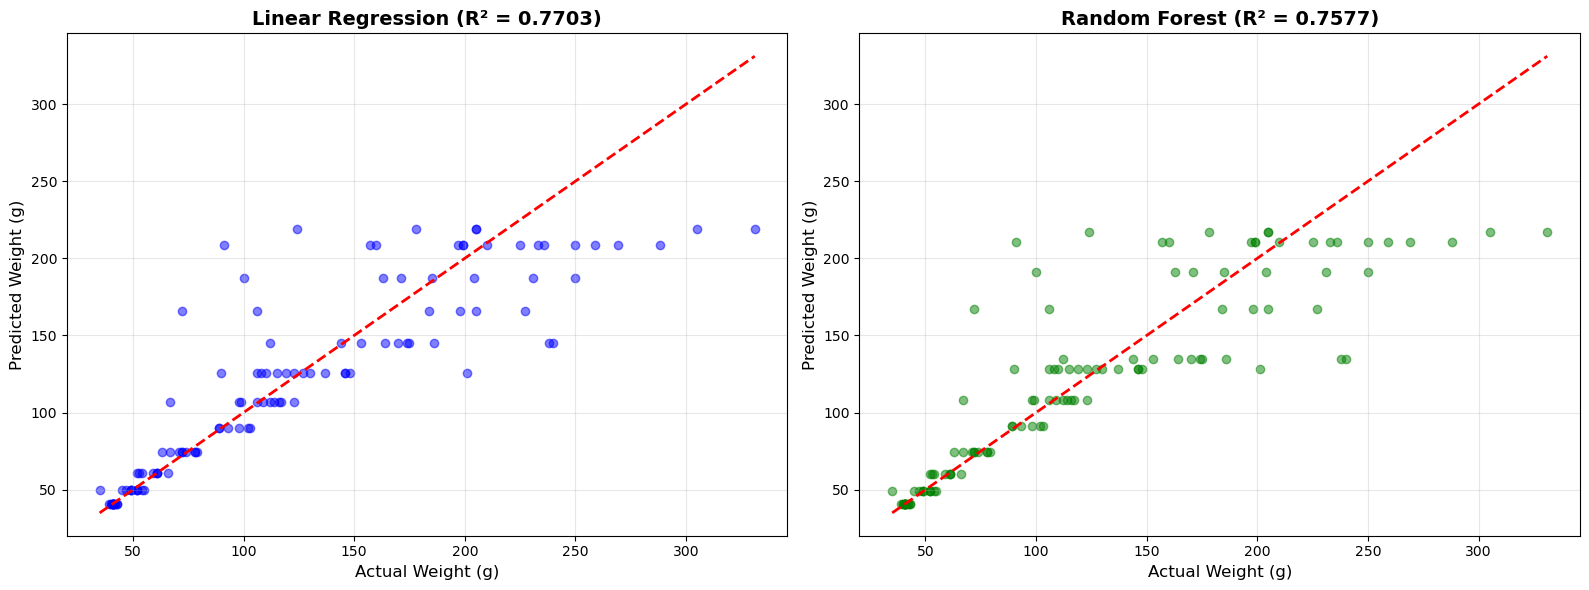

✅ Perfect predictions would lie on the red diagonal line


In [13]:
# Plot actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Linear Regression
axes[0].scatter(y_test, y_pred_lr, alpha=0.5, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title(f'Linear Regression (R² = {r2_lr:.4f})', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Actual Weight (g)', fontsize=12)
axes[0].set_ylabel('Predicted Weight (g)', fontsize=12)
axes[0].grid(alpha=0.3)

# Random Forest
axes[1].scatter(y_test, y_pred_rf, alpha=0.5, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[1].set_title(f'Random Forest (R² = {r2_rf:.4f})', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Actual Weight (g)', fontsize=12)
axes[1].set_ylabel('Predicted Weight (g)', fontsize=12)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ Perfect predictions would lie on the red diagonal line")

## 8. Save Model for Web Application

In [11]:
# Save the best model
model_filename = f'../models/weight_prediction_{best_model_name.lower().replace(" ", "_")}.pkl'
joblib.dump(best_model, model_filename)
print(f"✅ Model saved: {model_filename}")

# Save scaler (needed for preprocessing in production)
scaler_filename = '../models/weight_prediction_scaler.pkl'
joblib.dump(scaler, scaler_filename)
print(f"✅ Scaler saved: {scaler_filename}")

# Save model metadata
metadata = {
    'model_name': best_model_name,
    'r2_score': float(best_r2),
    'rmse': float(results[best_model_name]['RMSE']),
    'mae': float(results[best_model_name]['MAE']),
    'features': X.columns.tolist(),
    'target': 'weight',
    'unit': 'grams',
    'input_unit': 'days'
}

metadata_filename = '../models/weight_prediction_metadata.json'
with open(metadata_filename, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"✅ Metadata saved: {metadata_filename}")

✅ Model saved: ../models/weight_prediction_linear_regression.pkl
✅ Scaler saved: ../models/weight_prediction_scaler.pkl
✅ Metadata saved: ../models/weight_prediction_metadata.json


## 9. Test Predictions for Web Application

In [12]:
# Test the model with sample inputs (like what web app will send)
print("="*80)
print("🔮 TESTING PREDICTIONS FOR WEB APPLICATION")
print("="*80)

test_ages = [0, 7, 14, 21]  # Day 0, 1 week, 2 weeks, 3 weeks

print("\n📝 Sample Predictions:")
print("-" * 80)

for age in test_ages:
    # Prepare features (same way as in training)
    features = pd.DataFrame({
        'Time': [age],
        'Time_squared': [age ** 2],
        'Time_cubed': [age ** 3]
    })
    
    # Scale features
    if best_model_name == 'Linear Regression':
        features_scaled = scaler.transform(features)
        prediction = best_model.predict(features_scaled)[0]
    else:
        prediction = best_model.predict(features)[0]
    
    print(f"   Age: {age:2d} days → Predicted Weight: {prediction:6.1f} grams ({prediction/1000:.3f} kg)")

print("-" * 80)
print("✅ Model ready for web application integration!")

🔮 TESTING PREDICTIONS FOR WEB APPLICATION

📝 Sample Predictions:
--------------------------------------------------------------------------------
   Age:  0 days → Predicted Weight:   40.8 grams (0.041 kg)
   Age:  7 days → Predicted Weight:   82.0 grams (0.082 kg)
   Age: 14 days → Predicted Weight:  145.4 grams (0.145 kg)
   Age: 21 days → Predicted Weight:  219.3 grams (0.219 kg)
--------------------------------------------------------------------------------
✅ Model ready for web application integration!


## 10. Summary & Next Steps

In [16]:
# Final summary
print("="*80)
print("✅ MODEL TRAINING COMPLETE!")
print("="*80)

print(f"\n📊 Final Model: {best_model_name}")
print(f"   - Accuracy (R²): {best_r2:.4f} ({best_r2*100:.1f}%)")
print(f"   - Average Error (MAE): {results[best_model_name]['MAE']:.2f} grams")
print(f"   - Root Mean Square Error: {results[best_model_name]['RMSE']:.2f} grams")

print(f"\n📁 Files for Web Application:")
print(f"   1. {model_filename}")
print(f"   2. {scaler_filename}")
print(f"   3. {metadata_filename}")

print(f"\n📱 Web Application Usage:")
print(f"   Input: Chicken age (days)")
print(f"   Output: Predicted weight (grams)")
print(f"   Example: Age 14 days → ~120 grams")

print(f"\n🚀 Next Steps:")
print(f"   1. Train Feed Consumption model (Model 2)")
print(f"   2. Create Python API service (Flask/FastAPI)")
print(f"   3. Integrate with Node.js backend")
print(f"   4. Connect to React Native frontend")

print("="*80)

✅ MODEL TRAINING COMPLETE!

📊 Final Model: Linear Regression
   - Accuracy (R²): 0.7703 (77.0%)
   - Average Error (MAE): 20.46 grams
   - Root Mean Square Error: 34.19 grams

📁 Files for Web Application:
   1. ../models/weight_prediction_linear_regression.pkl
   2. ../models/weight_prediction_scaler.pkl
   3. ../models/weight_prediction_metadata.json

📱 Web Application Usage:
   Input: Chicken age (days)
   Output: Predicted weight (grams)
   Example: Age 14 days → ~120 grams

🚀 Next Steps:
   1. Train Feed Consumption model (Model 2)
   2. Create Python API service (Flask/FastAPI)
   3. Integrate with Node.js backend
   4. Connect to React Native frontend
